In [8]:
import torch
import os 
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image


In [9]:
class ImageProcessor:
    def __init__(self,root_dir_path,transformations=None):
        self.root_dir_path=root_dir_path
        self.transformations=transformations

        self.all_img_paths=[os.path.join(root_dir_path,img)for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, key):
        img_path=self.all_img_paths[key]
        img=Image.open(img_path).convert('RGB')

        if self.transformations:
            img=self.transformations(img)
        return img

In [25]:
root_dir_path='./img_align_celeba/'
transformations=transforms.Compose([
    transforms.CenterCrop(174),
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)
)])

In [26]:
dataset=ImageProcessor(root_dir_path,transformations)
print(f'loaded {len(dataset)} images')

loaded 202599 images


In [27]:
dataloader=DataLoader(dataset,batch_size=128,shuffle=True)

In [28]:
import torch.nn as nn
import torch.optim as optim 
import numpy as np

Generator

In [42]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3):
        super(Generator,self).__init__()
        self.model=nn.Sequential(
            nn.Linear(z_dim,256),
            nn.ReLU(),
            nn.Linear(256,512),
            nn.ReLU(),
            nn.Linear(512,1024),
            nn.ReLU(),
            nn.Linear(1024,64*64*img_channels),
            nn.Tanh()
        )

    def forward(self,z):
        img=self.model(z)
        img=img.view(img.size(0),3,64,64)
        return img

Dicrimenator

In [43]:
class Discrimenator(nn.Module):
    def __init__(self, img_channels=3):
        super(Discrimenator,self).__init__()
        self.model=nn.Sequential(
            nn.Flatten(),
            nn.Linear(img_channels*64*64,1024),
            nn.LeakyReLU(0.2,inplace=True),

            nn.Linear(1024,512),
            nn.LeakyReLU(0.2,inplace=True),
            nn.Linear(512,256),
            nn.LeakyReLU(0.2,inplace=True),
            nn.Linear(256,1),
            nn.Sigmoid()
        )

    def forward(self,img):
        return self.model(img)

In [44]:
GAN_loss=nn.BCELoss()
gen=Generator()
g_optim=optim.Adam(gen.parameters(),lr=0.002,betas=(0.5,0.999))

discim=Discrimenator()
dis_optim=optim.Adam(discim.parameters(),lr=0.0002,betas=(0.5,0.999))

In [45]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is cpu


In [46]:
generator = gen.to(device)
discriminator = discim.to(device)

In [47]:
generator

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): ReLU()
    (6): Linear(in_features=1024, out_features=12288, bias=True)
    (7): Tanh()
  )
)

In [48]:
discriminator

Discrimenator(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=1024, bias=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): LeakyReLU(negative_slope=0.2, inplace=True)
    (7): Linear(in_features=256, out_features=1, bias=True)
    (8): Sigmoid()
  )
)

training GAN

In [49]:
def train(Generator,Discriminator,dataloader,epochs=5):
    for epoch in range(epochs):
        for i,img in enumerate(dataloader):
            real_imgs=img.to(device)
            batch_size=real_imgs.size(0)

            real_labels=torch.ones(batch_size,1).to(device)
            fake_labels=torch.zeros(batch_size,1).to(device)

            dis_optim.zero_grad()

            fake_imgs=Generator(torch.randn(batch_size,100).to(device))

            real_loss=GAN_loss(Discriminator(real_imgs),real_labels)
            fake_loss=GAN_loss(Discriminator(fake_imgs.detach()),fake_labels)

            d_loss=(real_loss+fake_loss)/2

            d_loss.backward()
            dis_optim.step()

            g_optim.zero_grad()
            g_loss=GAN_loss(Discriminator(fake_imgs),real_labels)
            g_loss.backward()
            g_optim.step()

            if i % 50 == 0:
                print(f'for epoch:{epoch+1}/{epochs}..batch:{i+1}..G_loss:{g_loss}... D_lodd:{d_loss}')

        save_generated_images(Generator,epoch,device)

In [50]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch:1/5..batch:1..G_loss:0.716262936592102... D_lodd:0.6964269876480103
for epoch:1/5..batch:51..G_loss:0.696027398109436... D_lodd:0.5148953199386597
for epoch:1/5..batch:101..G_loss:0.9262511730194092... D_lodd:0.5752413272857666
for epoch:1/5..batch:151..G_loss:0.8223094940185547... D_lodd:0.5643516778945923
for epoch:1/5..batch:201..G_loss:0.7708417177200317... D_lodd:0.466442346572876
for epoch:1/5..batch:251..G_loss:0.9492787718772888... D_lodd:0.5723909735679626
for epoch:1/5..batch:301..G_loss:0.9140670895576477... D_lodd:0.5906798243522644
for epoch:1/5..batch:351..G_loss:0.7023724913597107... D_lodd:0.6170629858970642
for epoch:1/5..batch:401..G_loss:0.871951699256897... D_lodd:0.7840688824653625
for epoch:1/5..batch:451..G_loss:0.8280454874038696... D_lodd:0.7588916420936584
for epoch:1/5..batch:501..G_loss:0.9995038509368896... D_lodd:0.49545058608055115
for epoch:1/5..batch:551..G_loss:1.2981418371200562... D_lodd:0.6933683753013611
for epoch:1/5..batch:601..G_loss:0

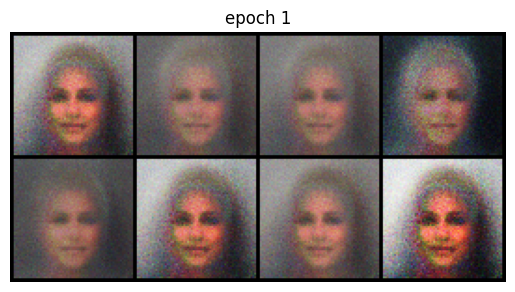

for epoch:2/5..batch:1..G_loss:0.7884953022003174... D_lodd:0.6713981628417969
for epoch:2/5..batch:51..G_loss:0.7918319702148438... D_lodd:0.6801280975341797
for epoch:2/5..batch:101..G_loss:0.7825497984886169... D_lodd:0.6979560852050781
for epoch:2/5..batch:151..G_loss:1.1573517322540283... D_lodd:0.6345925331115723
for epoch:2/5..batch:201..G_loss:0.8028517365455627... D_lodd:0.6312493085861206
for epoch:2/5..batch:251..G_loss:1.0187335014343262... D_lodd:0.6479178667068481
for epoch:2/5..batch:301..G_loss:0.8884978890419006... D_lodd:0.6139675378799438
for epoch:2/5..batch:351..G_loss:0.9277565479278564... D_lodd:0.6429226398468018
for epoch:2/5..batch:401..G_loss:0.8324305415153503... D_lodd:0.6482254266738892
for epoch:2/5..batch:451..G_loss:0.9525982737541199... D_lodd:0.6969608664512634
for epoch:2/5..batch:501..G_loss:0.8142858743667603... D_lodd:0.73515784740448
for epoch:2/5..batch:551..G_loss:0.9625496864318848... D_lodd:0.6880693435668945
for epoch:2/5..batch:601..G_loss:

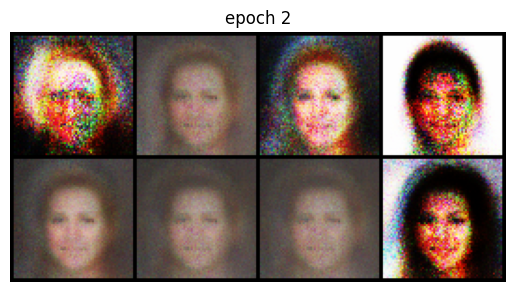

for epoch:3/5..batch:1..G_loss:0.7532504796981812... D_lodd:0.6873875856399536
for epoch:3/5..batch:51..G_loss:0.8310946822166443... D_lodd:0.6789295673370361
for epoch:3/5..batch:101..G_loss:0.7782346606254578... D_lodd:0.6531438827514648
for epoch:3/5..batch:151..G_loss:0.8532294034957886... D_lodd:0.6715990304946899
for epoch:3/5..batch:201..G_loss:0.6707602143287659... D_lodd:0.711840033531189
for epoch:3/5..batch:251..G_loss:0.8095448613166809... D_lodd:0.6667982339859009
for epoch:3/5..batch:301..G_loss:0.7990595102310181... D_lodd:0.6679949760437012
for epoch:3/5..batch:351..G_loss:0.8676990270614624... D_lodd:0.6820651292800903
for epoch:3/5..batch:401..G_loss:0.8103583455085754... D_lodd:0.5971735715866089
for epoch:3/5..batch:451..G_loss:0.7587634325027466... D_lodd:0.7089868187904358
for epoch:3/5..batch:501..G_loss:0.8629469871520996... D_lodd:0.686382532119751
for epoch:3/5..batch:551..G_loss:0.7592453956604004... D_lodd:0.6765883564949036
for epoch:3/5..batch:601..G_loss:

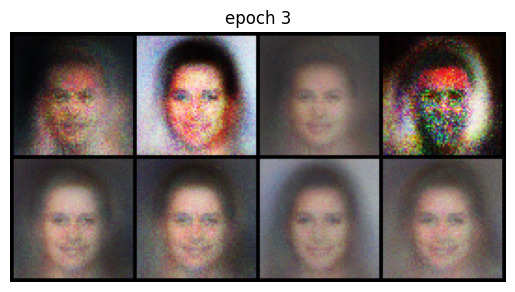

for epoch:4/5..batch:1..G_loss:0.7087671756744385... D_lodd:0.6945359706878662
for epoch:4/5..batch:51..G_loss:0.8477238416671753... D_lodd:0.6485980749130249
for epoch:4/5..batch:101..G_loss:0.7634063363075256... D_lodd:0.6713273525238037
for epoch:4/5..batch:151..G_loss:0.7534403800964355... D_lodd:0.6819584369659424
for epoch:4/5..batch:201..G_loss:0.848810076713562... D_lodd:0.662179708480835
for epoch:4/5..batch:251..G_loss:0.7841008305549622... D_lodd:0.6533290147781372
for epoch:4/5..batch:301..G_loss:0.8682570457458496... D_lodd:0.6628942489624023
for epoch:4/5..batch:351..G_loss:0.747094988822937... D_lodd:0.666833758354187
for epoch:4/5..batch:401..G_loss:0.765932023525238... D_lodd:0.7158569097518921
for epoch:4/5..batch:451..G_loss:0.9085646867752075... D_lodd:0.7164900898933411
for epoch:4/5..batch:501..G_loss:0.7797062397003174... D_lodd:0.7002066969871521
for epoch:4/5..batch:551..G_loss:0.8995303511619568... D_lodd:0.671751856803894
for epoch:4/5..batch:601..G_loss:0.73

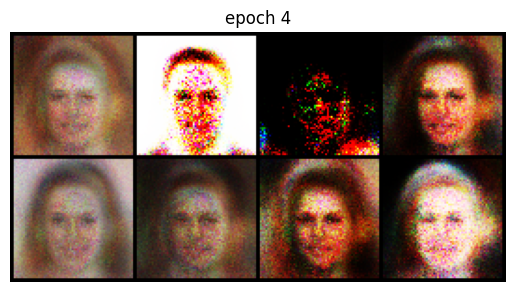

for epoch:5/5..batch:1..G_loss:0.8139309883117676... D_lodd:0.6448507308959961
for epoch:5/5..batch:51..G_loss:0.7770443558692932... D_lodd:0.6780391931533813
for epoch:5/5..batch:101..G_loss:0.8750053644180298... D_lodd:0.7458994388580322
for epoch:5/5..batch:151..G_loss:0.8039481043815613... D_lodd:0.6839706301689148
for epoch:5/5..batch:201..G_loss:0.8409204483032227... D_lodd:0.6731294393539429
for epoch:5/5..batch:251..G_loss:0.7382898330688477... D_lodd:0.674272894859314
for epoch:5/5..batch:301..G_loss:0.7610633373260498... D_lodd:0.6764189004898071
for epoch:5/5..batch:351..G_loss:0.785588264465332... D_lodd:0.6732416749000549
for epoch:5/5..batch:401..G_loss:0.720704197883606... D_lodd:0.7101632356643677
for epoch:5/5..batch:451..G_loss:0.7707366943359375... D_lodd:0.6669797897338867
for epoch:5/5..batch:501..G_loss:0.9703127145767212... D_lodd:0.7264344692230225
for epoch:5/5..batch:551..G_loss:0.831592857837677... D_lodd:0.6890710592269897
for epoch:5/5..batch:601..G_loss:0.

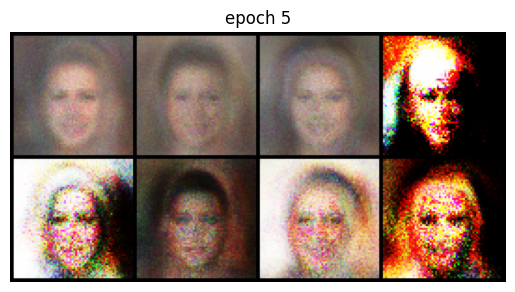

In [51]:
train(generator, discriminator, dataloader, epochs=5)